# 03 · Edge benchmark, tuning and recommendation

The question changes from *"which model predicts best?"* to *"which model gives the right trade-off between
predictive quality, compute, model size, feature burden and interpretability?"*

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
FIG = REPORTS / "figures"
results = json.loads((REPORTS / "results.json").read_text())
pd.set_option("display.precision", 4)

## Benchmark environment

Timings depend on hardware, so they are always reported together with the machine they came from.

In [2]:
pd.Series(results["environment"], name="value").to_frame()

,value
platform,Linux-6.18.44-fc-v470-x86_64-with-glibc2.39
processor,x86_64
python,3.13.18
logical_cpu_cores,2
torch_version,2.15.0+cu132
pytorch_training_device,cpu
gpu,none


Every model is serialized (joblib or PyTorch `state_dict`) to measure its size. Inference runs on
**CPU with one thread**, after warm-up predictions: the median of repeated single-window predictions, plus one
batch of 1,000 test windows.

## Feature importance: a second view

Spearman correlation, impurity vs. permutation ranking: -0.51


,perm_mean,perm_std,impurity_rank
feature,,,
fBodyAccMag_std,0.0288,0.0029,20
tGravityAcc_arCoeff_X_1,0.0158,0.0032,18
tGravityAcc_arCoeff_Y_2,0.0154,0.0025,13
tBodyAccMag_std,0.0080,0.0032,12
tGravityAcc_min_Z,0.0052,0.0016,15
tGravityAcc_arCoeff_Y_3,0.0035,0.0021,24
fBodyAccJerk_bandsEnergy_1_16,0.0028,0.0013,11
tGravityAcc_min_X,0.0022,0.0013,3
angle_Z_gravityMean,0.0018,0.0012,19


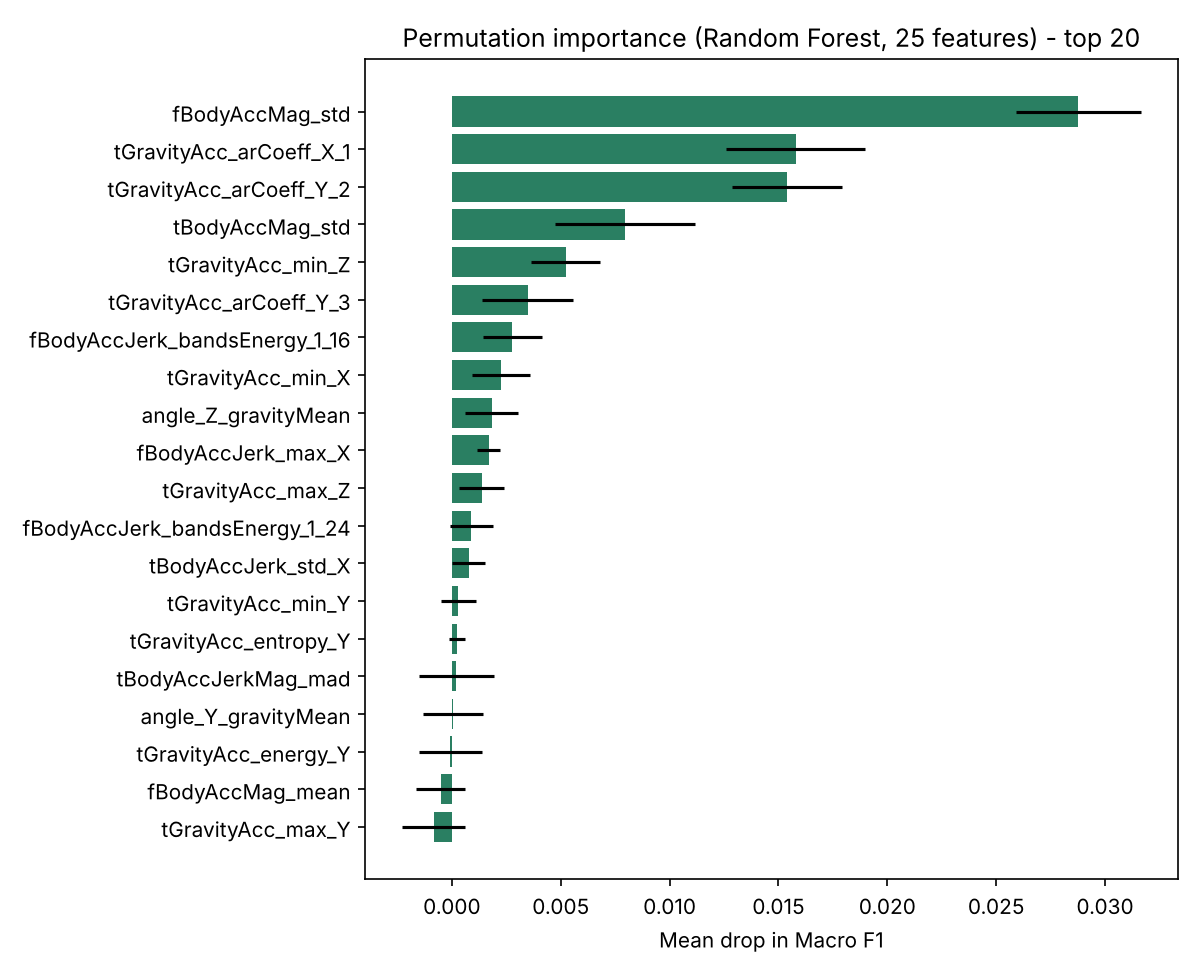

In [3]:
perm = pd.read_csv(REPORTS / "permutation_importance.csv", index_col=0)
print(f"Spearman correlation, impurity vs. permutation ranking: {results['impurity_vs_permutation_spearman']:.2f}")
display(perm.head(10).round(4))
display(Image(FIG / "permutation_importance.png", width=600))

Permutation importance (on the 25-feature Random Forest, scored by Macro F1) shows how much the
predictions depend on each feature. Movement-intensity features (`fBodyAccMag_std`, `tBodyAccMag_std`) and
gravity autoregression coefficients matter most. The ranking disagrees strongly with impurity importance
(Spearman ρ ≈ −0.5): `tGravityAcc_mean_X` ranks first by impurity but near zero by permutation, because many
gravity features are correlated and can stand in for one another. Permutation importance describes how much
the model relies on a feature for these test subjects, **not** a causal effect.

## Hyperparameter search

A `RandomizedSearchCV` (6 configurations) tunes the Random Forest's `n_estimators`, `max_depth`,
`min_samples_leaf` and `max_features`, using the grouped CV on the development subjects only. The tuned model
is then evaluated once on the test subjects.

In [4]:
hpo = results["hpo"]
print("Best parameters:", hpo["best_params"])
print(f"Grouped-CV Macro F1: {hpo['cv_macro_f1']:.4f} | Test Macro F1: {hpo['test_macro_f1']:.4f}")
cv = pd.read_csv(REPORTS / "hpo_cv_results.csv")
cv[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score")

Best parameters: {'n_estimators': 150, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 25}
Grouped-CV Macro F1: 0.9261 | Test Macro F1: 0.9444


,params,mean_test_score,std_test_score,rank_test_score
1,"{'n_estimators': 150, 'min_samples_leaf': 2, '...",0.9261,0.0202,1
2,"{'n_estimators': 100, 'min_samples_leaf': 2, '...",0.9255,0.0207,2
3,"{'n_estimators': 100, 'min_samples_leaf': 2, '...",0.9255,0.0207,2
4,"{'n_estimators': 200, 'min_samples_leaf': 4, '...",0.9225,0.0162,4
5,"{'n_estimators': 200, 'min_samples_leaf': 2, '...",0.9197,0.0160,5
0,"{'n_estimators': 150, 'min_samples_leaf': 1, '...",0.9170,0.0173,6


The search picked 150 trees, depth 25, `min_samples_leaf=2` and `max_features="log2"`. On the
test subjects the tuned forest improves on the default one by about 1.7 points (0.944 vs. 0.927) and is also
smaller and faster, but it is still below Logistic Regression. Note the standard deviation across folds
(about 2 points): differences of that size between models are within the noise of six held-out people.

The run is logged to MLflow (parameters, grouped-CV and test metrics, and the decision table as an artifact).
To browse it locally: `mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db`.

## Final evidence table

In [5]:
decision = pd.read_csv(REPORTS / "decision_table.csv")
decision

,model,macro_f1,accuracy,train_time_s,n_features,size_mb,single_window_latency_ms,batch_latency_ms
0,Logistic Regression (561),0.9657,0.9641,1.7036,561,0.0536,0.2919,4.4629
1,Random Forest tuned (561),0.9444,0.9475,3.2938,561,13.5301,10.1697,24.4702
2,LightGBM (561),0.9421,0.9409,41.6738,561,4.1698,1.6200,124.4530
3,PyTorch MLP (561),0.9368,0.9344,4.0660,561,0.3104,0.0923,5.3645
4,Random Forest (561),0.9270,0.9283,14.8062,561,19.8143,22.4621,51.3610
5,Random Forest (25),0.8784,0.8788,3.0068,25,18.9724,22.5222,33.7319
6,LightGBM (25),0.8737,0.8714,3.1865,25,5.3722,1.2204,172.5696


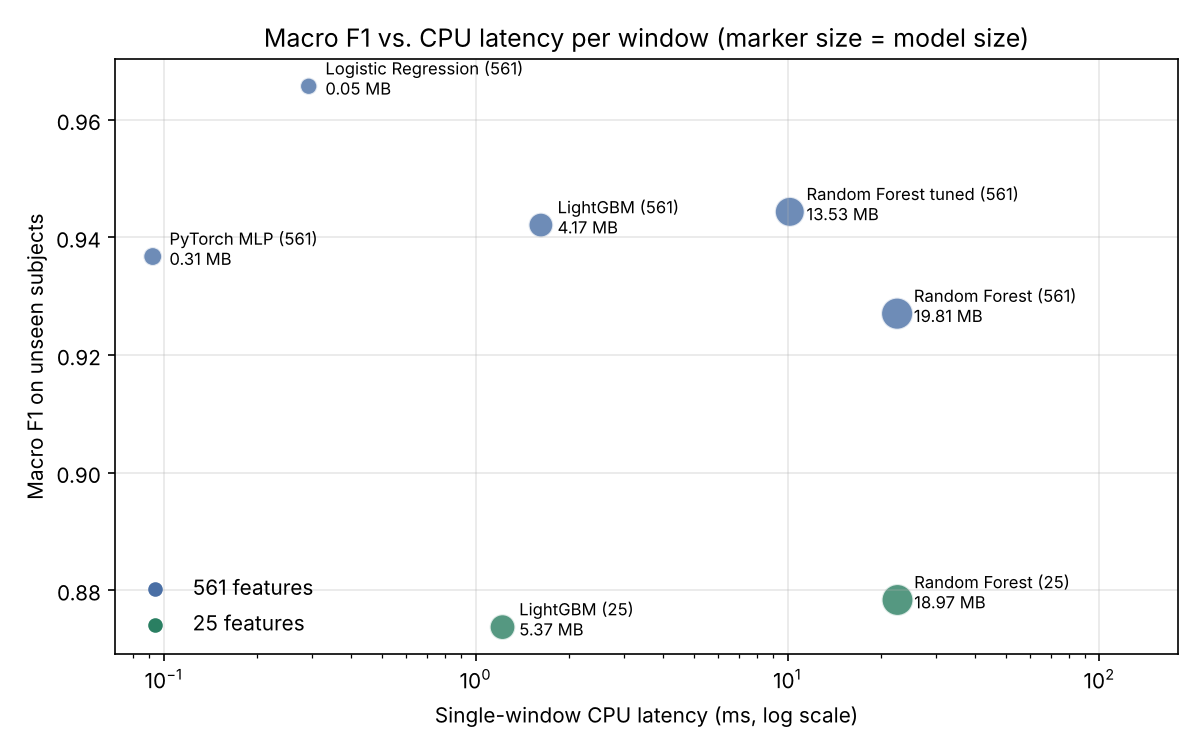

In [6]:
display(Image(FIG / "tradeoff.png", width=700))

| Criterion | Best model | Value |
|---|---|---|
| Macro F1 | Logistic Regression (561) | 0.966 |
| Training time | Logistic Regression (561) | 1.7 s |
| Single-window latency | PyTorch MLP | 0.09 ms |
| Model size | Logistic Regression (561) | 0.05 MB |

- **Logistic Regression** combines the best Macro F1 with the smallest model and fast inference (0.29 ms
  per window).
- The **MLP** predicts fastest (0.09 ms) at only 0.31 MB, but its Macro F1 is 2.9 points lower, so PyTorch
  brings no measurable predictive advantage.
- The **Random Forests** are the least edge-friendly: 14–20 MB and 10–22 ms per window, because their size
  depends on the number and depth of trees, not on the number of inputs.
- **Reducing 561 → 25 features** cuts on-device feature extraction but costs 5–7 Macro F1 points, and brings
  almost no gain in size or latency (LightGBM: 4.2 → 5.4 MB, 1.6 → 1.2 ms).
- **Interpretability** favours Logistic Regression (per-class coefficients) and the tree models (feature
  importance); the MLP is the hardest to explain.
- **Serious candidates:** Logistic Regression (561) as the best overall trade-off, and LightGBM (25) as a
  low-feature alternative.

## Recommendation

**Deploy Logistic Regression on all 561 features.**

- **Predictive performance.** On six unseen people it has the highest Macro F1 (**0.966**) and accuracy
  (0.964), about 2 points ahead of the tuned Random Forest and LightGBM. Its remaining errors are concentrated
  between sitting and standing (F1 0.924 and 0.928); moving activities and laying reach F1 ≥ 0.977.
- **Compute.** Training takes under 2 s on a laptop-class CPU. Inference takes **0.29 ms** per window, far
  faster than the Random Forests (10–22 ms).
- **Footprint.** The model is only **0.05 MB**, compared with 14–20 MB for the Random Forests and 4–5 MB for
  LightGBM. Its main cost is that all 561 features must be computed on the device. The 25-feature models
  reduce this burden but lose 5–7 Macro F1 points without saving size or latency.
- **Interpretability.** Per-class coefficients show which signals drive each prediction, which supports
  debugging and user trust in a health-related product.
- **Deep learning.** The MLP is the fastest at inference but scores 2.9 points lower and adds a PyTorch
  runtime, so it offers no practical advantage on engineered features.
- **Trade-off.** We gain top accuracy, a tiny model, sub-millisecond inference and transparency. We give up
  the lower feature-extraction cost of the reduced models.

## Limitations and next steps

- **Small test group.** Results rest on six held-out people, and the same test set is used to compare the
  candidates. Fold-to-fold variation in cross-validation (about 2 points) is as large as some gaps between
  models. Next: leave-subjects-out cross-validation for every model, with confidence intervals.
- **Feature extraction not measured.** The benchmark times the model only. Computing 561 features on a
  wearable is likely the real cost. Next: benchmark the full pipeline (feature extraction, inference and
  energy use) on the target hardware, comparing Logistic Regression with LightGBM (25).
- **Timings come from a 2-core cloud CPU** and will differ on a microcontroller-class device.